# 10 · The search, and a network where it is unsure

Every network so far worked on the whole picture and hedged there (notebooks 2 and 3). This
one keeps the published tile search's N+1 wherever the search can account for what moved, and
lets a network correct it only where it cannot - a mask from the search's own confidence:

**out = the search's N+1 + g · r**

- **u, the confidence, per 16 px cell**: N−2 moved by the search's whole motion should be N.
  `u` is how much of the change between them that motion leaves unexplained - the mean
  |N − N−2 moved| over the mean |N − N−2| (+1 luma level), clipped to 0..1: 0 where one motion
  explains the cell, 1 where it explains nothing (a dragged window over a still desktop, a
  region scrolling inside a page, a menu).
- **g, the gate**: sigmoid(a·u + b) per pixel, `a` and `b` learned - the mask, soft, and how
  readily it opens left to training.
- **r, the correction**: notebook 2's two-scale network, given N, the search's N+1, the residual
  |N − N−2 moved|, `u` and the tile's motion. Its last convolution starts at zero, so untrained
  the model *is* the search, and a still tile comes back as it was.

(`models.Masked`.) Trained on whole client tiles (328×188), not the run set's 80 px spots: the
mask is about where in a tile one motion fails. Beside it, two controls: the same network with
the gate held open (g = 1), and the mask with no network at all - repeat N wherever `u` is over
a threshold, the fallback a TV's frame-rate converter uses where its motion is unreliable.

**What to expect.** Notebook 9 found that where the search is unsure, what it lacks is mostly
not where the content went but whether it went on: a drag changes speed, a region stops. A
network on two frames cannot know that either - so its best bet there may be to hold back, and
the score is chosen to credit that: epochs are kept by the **moving** tiles capped at 50 dB
(notebooks 6 to 9), where a stop counts. The learned gate reports itself: if it shuts, the
network has nothing to add where the search is unsure.

Steps:

1. **Data** - moving whole tiles from every train clip, and from the validation clips to choose epochs.
2. **The mask before training** - where `u` is high, how much of the search's error is there, and the fallback's threshold.
3. **Training** - the gated network and the open one.
4. **Validation** - every client tile of the 115 validation clips, beside the search, the pyramid and the fallback.
5. **By what happened** - notebook 7's families, and where the gate opens.
6. **One tile** - the mask, the gate and the correction drawn.
7. **Work** - what the network costs beside the search.

Needs: `00_data_preprocess.ipynb` and the sources it read. Writes `tiles_train` and `tiles_val`
into the data folder (~7 GB) and the trainings into `checkpoints/masked_runs/`; nothing is
exported.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import budget, history, masked, models, recursive, runs, show, speed, training
from helpers.recursive import FAMILIES, family
from helpers.training import DEVICE

STILL, SHARPNESS, CAP = 0.1, 10.0, 50.0
PER_CLIP = {"train": 16, "val": 8}           # moving tiles cut from each clip
LEARNING_RATE, BATCH_SIZE, PATIENCE = 1e-3, 16, 4
RUN_DIR = training.CHECKPOINT_DIR / "masked_runs"
CACHE = training.CHECKPOINT_DIR / "masked"
SEED = 0
training.seed_everything(SEED)

manifest = training.load_manifest()
training.describe(manifest)
FRACTION = 1 / runs.received_every(manifest)


def tile_search():
    return models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL)


published = tile_search().to(DEVICE).eval()
pyramid = models.PyramidSearch(((4, 4, 1), (2, 1, 2), (1, 2, 4)), SHARPNESS, FRACTION, STILL, "equiangular",
                               whole=True).to(DEVICE).eval()
search_model = models.Motion(search=published, learned=False).to(DEVICE).eval()

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)


## 1. Data

Per clip, 16 tiles where the published search's gate is open, at random received frames -
frames N−2, N and N+1 of each, and its label (notebook 7). The validation tiles (8 a clip)
choose the epoch; section 4 scores every tile of every validation clip again.

In [2]:
tiles = {}
for split, per_clip in PER_CLIP.items():
    started = time.time()
    tiles[split] = masked.load(split) or masked.build(manifest, split, published, per_clip, seed=SEED)
    frames, meta = tiles[split]
    print(f"{split}: {len(frames)} moving tiles from {len(set(meta['source']))} clips "
          f"({frames.nbytes / 1e9:.1f} GB, {time.time() - started:.0f}s)")
val_families = np.array([family(label) for label in tiles["val"][1]["label"]])
train_families = np.array([family(label) for label in tiles["train"][1]["label"]])
print(f"\n{'':<26}" + "".join(f"{name:>24}" for name in FAMILIES))
for split, found in (("train", train_families), ("val", val_families)):
    print(f"{split:<26}" + "".join(f"{(found == name).mean():24.1%}" for name in FAMILIES))

train: 11125 moving tiles from 730 clips (6.2 GB, 14s)
val: 854 moving tiles from 111 clips (0.5 GB, 1s)

                                  whole tile moves  part of the tile moves             unannounced                   video                   other
train                                        24.3%                   15.9%                    1.3%                   36.2%                   22.3%
val                                          41.2%                   18.3%                    2.2%                    9.4%                   28.9%


## 2. The mask before training

The untrained model's `u` on the validation tiles, against the search's error there: per band
of `u`, the share of the kept pixels and the share of the search's weighted squared error -
and of repeat's, and of the better of the two per cell (it sees N+1). Where `u` is high and
the search's error is concentrated, a mask has something to act on; where repeat is not better
there either, falling back to it gains nothing.

Then **the fallback**: N wherever `u` is over a threshold, the search's N+1 elsewhere - no
network. The threshold is chosen on 3,000 train tiles.

In [3]:
untrained = models.Masked(tile_search()).to(DEVICE).eval()
BANDS = [(0.0, 0.1), (0.1, 0.3), (0.3, 0.6), (0.6, 1.01)]


@torch.no_grad()
def by_band(frames, meta, cell=16):
    """Summed pixels and weighted squared errors (search, repeat, best of both per cell) per band of u."""
    sums = np.zeros((len(BANDS), 4))
    for first in range(0, len(frames), 32):
        previous, current, target = training.to_tensor(frames[first:first + 32]).unbind(1)
        parts = untrained.parts(previous, current)
        errors = budget.squared(torch.stack([parts["search"], current], 1), target)   # (N, 2, H, W)
        cells = torch.nn.functional.avg_pool2d(errors, cell, ceil_mode=True)
        search_better = (cells[:, :1] <= cells[:, 1:]).repeat_interleave(cell, 2).repeat_interleave(cell, 3)
        best = torch.where(search_better[..., :errors.shape[-2], :errors.shape[-1]], errors[:, :1], errors[:, 1:])
        for i, box in enumerate(meta["box"][first:first + 32]):
            y, x, h, w = box
            u = parts["u"][i, 0, y:y + h, x:x + w]
            kept = [e[i, 0, y:y + h, x:x + w] for e in (errors[:, :1], errors[:, 1:], best)]
            for b, (low, high) in enumerate(BANDS):
                inside = (u >= low) & (u < high)
                sums[b] += [inside.sum().item(), *(e[inside].sum().item() for e in kept)]
    return sums


sums = by_band(*tiles["val"])
print(f"{'u':<12}{'pixels':>10}{'search error':>15}{'repeat error':>15}{'best of both':>15}")
for (low, high), row in zip(BANDS, sums):
    print(f"{f'{low:.1f}-{min(high, 1):.1f}':<12}{row[0] / sums[:, 0].sum():10.1%}"
          + "".join(f"{row[k] / sums[:, 1].sum():15.1%}" for k in (1, 2, 3)))
print("(errors as shares of the search's total error)")


class Fallback(torch.nn.Module):
    """The search's N+1, and N where u is over `threshold` - the mask with no network."""

    def __init__(self, threshold):
        super().__init__()
        self.masked, self.threshold = untrained, threshold

    def forward(self, previous, current):
        parts = self.masked.parts(previous, current)
        return torch.where(parts["u"] > self.threshold, current, parts["search"])


subset = (tiles["train"][0][:3000], {key: value[:3000] for key, value in tiles["train"][1].items()})
base = np.minimum(masked.scores(search_model, *subset), CAP).mean()
print(f"\nthe fallback on 3,000 train tiles (moving, ≤ 50 dB): the search {base:.3f}")
found = {}
for threshold in (0.3, 0.5, 0.7, 0.8, 0.9, 0.95):
    found[threshold] = np.minimum(masked.scores(Fallback(threshold), *subset), CAP).mean()
    print(f"  N where u > {threshold:.2f}: {found[threshold]:.3f} ({found[threshold] - base:+.3f})")
THRESHOLD = max(found, key=found.get)
print(f"chosen: {THRESHOLD}")

u               pixels   search error   repeat error   best of both
0.0-0.1          44.2%          12.0%          41.0%          10.1%
0.1-0.3          16.4%           8.4%          29.0%           7.0%
0.3-0.6          21.4%          20.3%          45.9%          17.7%
0.6-1.0          18.0%          59.2%          67.0%          52.8%
(errors as shares of the search's total error)

the fallback on 3,000 train tiles (moving, ≤ 50 dB): the search 36.487
  N where u > 0.30: 35.779 (-0.707)
  N where u > 0.50: 36.168 (-0.319)
  N where u > 0.70: 36.383 (-0.103)
  N where u > 0.80: 36.440 (-0.046)
  N where u > 0.90: 36.469 (-0.018)
  N where u > 0.95: 36.479 (-0.007)
chosen: 0.95


## 3. Training

Both from the search (the correction at zero), Adam from 1e-3, batches of 16 whole tiles,
`metrics.luma_chroma_l1` over the window less the client's halo; an epoch is kept if it beats
the best so far on the moving validation tiles, capped at 50 dB, and the learning rate halves
after 4 epochs without - down to a hundredth, then training stops. Epoch 0 is the search: if
nothing beats it, the network has learned nothing worth keeping.


masked, gated
untrained (the search): 38.025 dB on the moving validation tiles, capped
epoch 1: loss 0.01145, 38.026 dB, lr 1.0e-03, gate a, b -0.07, -0.09, 16s
epoch 2: loss 0.01142, 38.026 dB (best), lr 1.0e-03, gate a, b -0.15, -0.22, 16s
epoch 3: loss 0.01144, 38.028 dB (best), lr 1.0e-03, gate a, b -0.24, -0.43, 16s
epoch 4: loss 0.01142, 38.034 dB (best), lr 1.0e-03, gate a, b -0.17, -0.67, 16s
epoch 5: loss 0.01142, 38.038 dB (best), lr 1.0e-03, gate a, b +0.07, -0.93, 17s
epoch 6: loss 0.01141, 38.045 dB (best), lr 1.0e-03, gate a, b +0.39, -1.12, 16s
epoch 7: loss 0.01138, 38.044 dB, lr 1.0e-03, gate a, b +0.71, -1.32, 16s
epoch 8: loss 0.01140, 38.053 dB (best), lr 1.0e-03, gate a, b +0.96, -1.48, 16s
epoch 9: loss 0.01137, 38.062 dB (best), lr 1.0e-03, gate a, b +1.20, -1.59, 16s
epoch 10: loss 0.01136, 38.063 dB, lr 1.0e-03, gate a, b +1.37, -1.72, 17s
epoch 11: loss 0.01131, 38.080 dB (best), lr 1.0e-03, gate a, b +1.49, -1.85, 17s
epoch 12: loss 0.01126, 38.074 dB, lr 1.

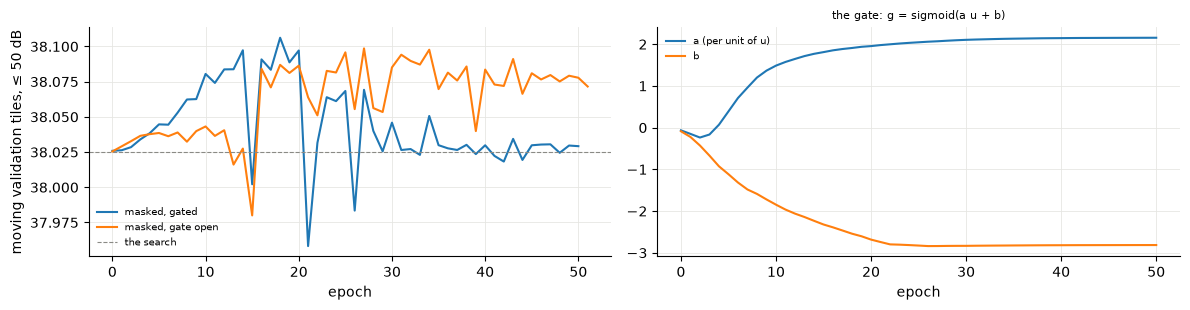

the kept gate: a = +1.91, b = -2.54: g = 0.07 where the search explains everything (u = 0), 0.35 where it explains nothing (u = 1)


In [4]:
builders = {"masked, gated": lambda: models.Masked(tile_search(), gated=True),
            "masked, gate open": lambda: models.Masked(tile_search(), gated=False)}
networks, histories, bests = {}, {}, {}
for name, build in builders.items():
    print(f"\n{'=' * 90}\n{name}\n{'=' * 90}")
    training.seed_everything(SEED)
    networks[name] = build().to(DEVICE)
    histories[name], bests[name] = masked.train(
        networks[name], tiles["train"][0], tiles["val"], RUN_DIR / f"{name.replace(', ', '_').replace(' ', '_')}.pt",
        LEARNING_RATE, BATCH_SIZE, PATIENCE)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for name, found in histories.items():
    axes[0].plot([h["score"] for h in found], label=name)
axes[0].axhline(np.minimum(masked.scores(search_model, *tiles["val"]), CAP).mean(), color="#8a8a85", ls="--", lw=0.8,
                label="the search")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("moving validation tiles, ≤ 50 dB")
axes[0].legend(fontsize=7, frameon=False)
gates = np.array([h["gate"] for h in histories["masked, gated"]])
axes[1].plot(gates[:, 0], label="a (per unit of u)")
axes[1].plot(gates[:, 1], label="b")
axes[1].set_xlabel("epoch")
axes[1].set_title("the gate: g = sigmoid(a u + b)", fontsize=8)
axes[1].legend(fontsize=7, frameon=False)
for ax in axes:
    ax.grid(color="#e6e6e3", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()
a, b = networks["masked, gated"].gate.detach().cpu().tolist()
print(f"the kept gate: a = {a:+.2f}, b = {b:+.2f}: g = {1 / (1 + np.exp(-b)):.2f} where the search explains "
      f"everything (u = 0), {1 / (1 + np.exp(-(a + b))):.2f} where it explains nothing (u = 1)")

## 4. Validation

Every client tile of the 115 validation clips at every received frame N from 6 on (notebooks
8 and 9's tiles), all methods on the same frames. Columns as in notebook 9: changed, all, the
moving tiles capped at 50 dB with the gain over the published search and its 95% range over
clips, and the moving tiles with the stop decided perfectly (the better of the method and
repeat per tile - a bound, it sees N+1).

In [5]:
CACHE.mkdir(parents=True, exist_ok=True)


def as_picture(model):
    model = model.to(DEVICE).eval()
    return lambda previous, current, target: model(previous, current)


PICTURES = {"repeat": lambda previous, current, target: current,
            "published search": as_picture(search_model),
            "pyramid, whole-pixel (notebook 8)": as_picture(models.Motion(search=pyramid, learned=False)),
            f"fallback: N where u > {THRESHOLD}": as_picture(Fallback(THRESHOLD)),
            **{name: as_picture(network) for name, network in networks.items()}}
path = CACHE / "val.pkl"
if path.exists() and path.stat().st_mtime > max((RUN_DIR / p).stat().st_mtime for p in ("masked_gated.pt", "masked_gate_open.pt")):
    val = pickle.loads(path.read_bytes())
else:
    started = time.time()
    val = recursive.load(manifest, "val", {}, PICTURES, published, pyramid, STILL)
    path.write_bytes(pickle.dumps(val))
    print(f"{len(val['tiles']['source'])} tiles in {time.time() - started:.0f}s")
assert set(val["wpsnr"]) == set(PICTURES)
table = val["tiles"]
moving, changed, clip_of, families = table["moving"], table["changed"], table["source"], table["family"]
ORDER = list(PICTURES)
BASE = "published search"
rng = np.random.default_rng(SEED)


def capped(name):
    return np.minimum(val["wpsnr"][name], CAP)


def stopped(name):
    return np.maximum(capped(name), capped("repeat"))


def over_clips(gain, mask, draws=2000):
    per = [gain[mask & (clip_of == c)] for c in np.unique(clip_of[mask])]
    means = [np.concatenate([per[i] for i in rng.integers(0, len(per), len(per))]).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])


print(f"{len(moving)} tiles from {len(set(clip_of))} clips: {moving.sum()} moving, {changed.sum()} changed\n")
print(f"{'wPSNR (dB)':<34}{'changed':>16}{'all':>16}{'moving, ≤ 50 dB':>18}{'95% over clips':>18}{'perfect stop':>14}")
for name in ORDER:
    s, base = val["wpsnr"][name], val["wpsnr"][BASE]
    gain = capped(name) - capped(BASE)
    low, high = over_clips(gain, moving) if name != BASE else (0, 0)
    print(f"{name:<34}{s[changed].mean():8.2f} ({s[changed].mean() - base[changed].mean():+5.2f})"
          f"{s.mean():8.2f} ({s.mean() - base.mean():+5.2f})"
          f"{capped(name)[moving].mean():10.2f} ({gain[moving].mean():+5.2f})  [{low:+.2f}, {high:+.2f}]"
          f"{stopped(name)[moving].mean():14.2f}")

12185 tiles in 106s
12185 tiles from 115 clips: 6722 moving, 4928 changed

wPSNR (dB)                                 changed             all   moving, ≤ 50 dB    95% over clips  perfect stop
repeat                               26.30 (-5.41)   61.39 (-1.44)     33.44 (-3.13)  [-4.20, -2.12]         33.44
published search                     31.71 (+0.00)   62.83 (+0.00)     36.57 (+0.00)  [+0.00, +0.00]         37.49
pyramid, whole-pixel (notebook 8)    31.99 (+0.27)   62.96 (+0.13)     36.61 (+0.04)  [-0.13, +0.22]         37.60
fallback: N where u > 0.95           31.79 (+0.07)   62.87 (+0.04)     36.64 (+0.06)  [-0.03, +0.17]         37.50
masked, gated                        31.66 (-0.05)   62.45 (-0.37)     36.63 (+0.06)  [-0.00, +0.12]         37.53
masked, gate open                    31.64 (-0.08)   62.48 (-0.35)     36.63 (+0.06)  [+0.01, +0.12]         37.52


## 5. By what happened

The moving tiles by family, raw and with the stop decided perfectly; the error budget of
notebook 7 (the share of the search's summed error each takes back, on the active tiles); and,
on the validation tiles of section 1, how far the gate opens - the mean `g` over the kept
pixels, and over the pixels where `u` > 0.5.

In [6]:
for title, score in (("moving, ≤ 50 dB", capped), ("moving, ≤ 50 dB, perfect stop", stopped)):
    print(f"{title:<34}" + "".join(f"{name:>24}" for name in FAMILIES))
    print(f"{'tiles':<34}" + "".join(f"{(moving & (families == f)).sum():24}" for f in FAMILIES))
    for name in ORDER:
        print(f"{name:<34}" + "".join(f"{score(name)[moving & (families == f)].mean():24.2f}" for f in FAMILIES))
    print()

active = moving | changed
error = val["error"]
print(f"{'taken back of the search error':<34}" + "".join(f"{name:>24}" for name in FAMILIES))
print(f"{'share of the search error':<34}" + "".join(f"{error[BASE][active & (families == f)].sum() / error[BASE][active].sum():24.1%}"
                                                     for f in FAMILIES))
for name in ORDER:
    print(f"{name:<34}" + "".join(f"{1 - error[name][active & (families == f)].sum() / error[BASE][active & (families == f)].sum():24.1%}"
                                  for f in FAMILIES))


@torch.no_grad()
def gate_by_family(network, frames, meta):
    total = {f: np.zeros(4) for f in FAMILIES}
    for first in range(0, len(frames), 32):
        previous, current, _ = training.to_tensor(frames[first:first + 32]).unbind(1)
        parts = network.parts(previous, current)
        for i, box in enumerate(meta["box"][first:first + 32]):
            y, x, h, w = box
            g, u = parts["gate"][i, 0, y:y + h, x:x + w], parts["u"][i, 0, y:y + h, x:x + w]
            unsure = u > 0.5
            total[val_families[first + i]] += [g.sum().item(), g.numel(), g[unsure].sum().item(), unsure.sum().item()]
    return total


found = gate_by_family(networks["masked, gated"].eval(), *tiles["val"])
print(f"\n{'the gate, validation tiles':<34}" + "".join(f"{name:>24}" for name in FAMILIES))
print(f"{'mean g':<34}" + "".join(f"{found[f][0] / max(found[f][1], 1):24.2f}" for f in FAMILIES))
print(f"{'share of pixels with u > 0.5':<34}" + "".join(f"{found[f][3] / max(found[f][1], 1):24.1%}" for f in FAMILIES))
print(f"{'mean g where u > 0.5':<34}" + "".join(f"{found[f][2] / max(found[f][3], 1):24.2f}" for f in FAMILIES))

moving, ≤ 50 dB                           whole tile moves  part of the tile moves             unannounced                   video                   other
tiles                                                 3440                    1034                     155                     809                    1284
repeat                                               27.04                   29.81                   24.05                   43.39                   48.36
published search                                     32.97                   29.99                   24.67                   43.78                   48.41
pyramid, whole-pixel (notebook 8)                    33.10                   29.88                   24.60                   43.73                   48.42
fallback: N where u > 0.95                           33.00                   30.13                   24.80                   43.97                   48.42
masked, gated                                        33.02            

## 6. One tile

Among the validation tiles of section 1 where part moves, the one where the gated network
gains most over the search and the one where it loses most: the change N → N+1, `u`, the gate
`g`, what the network added (`g · r`, in luma), and the errors of the search and of the
masked N+1 against it.

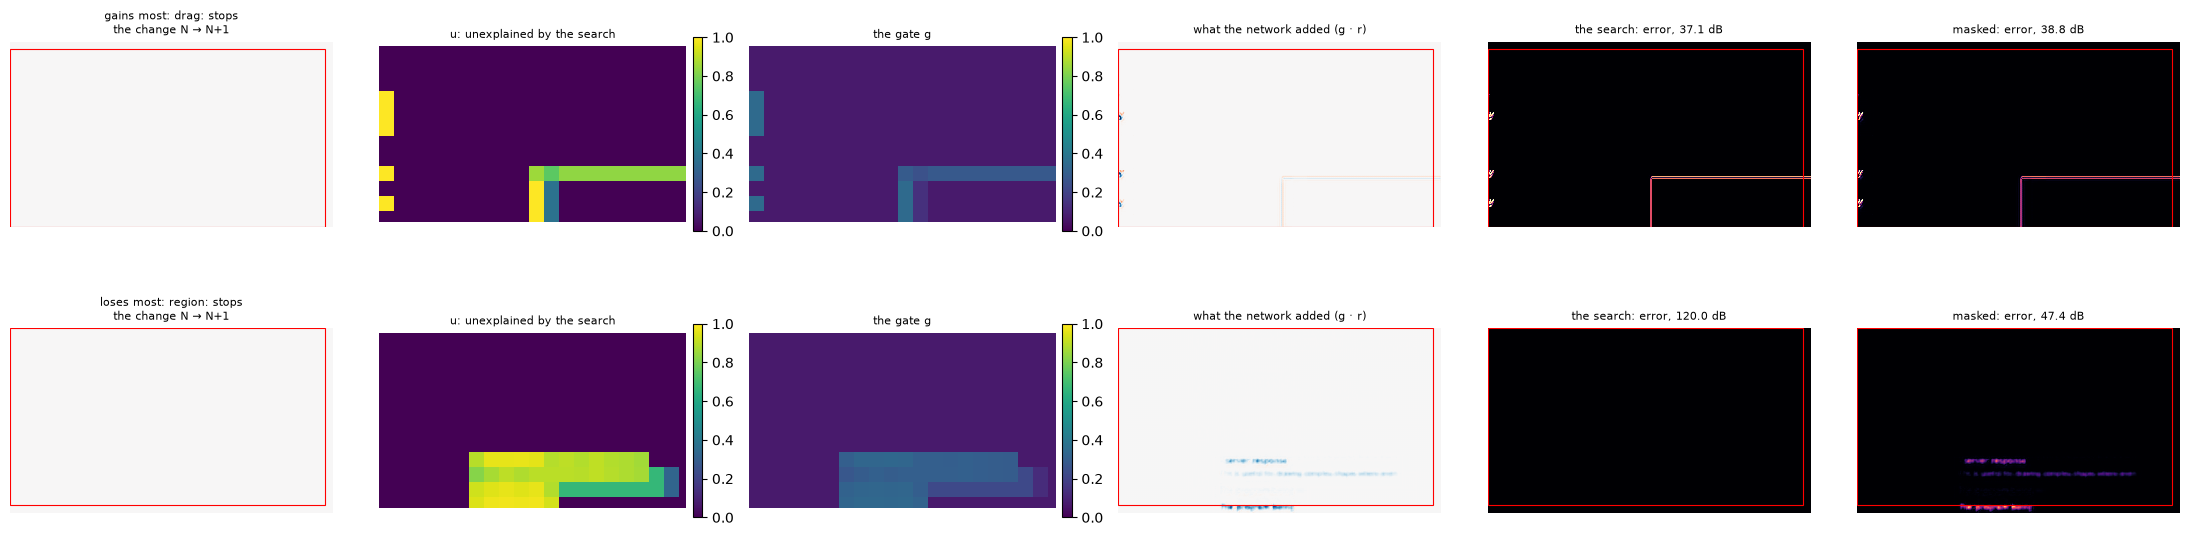

In [7]:
frames, meta = tiles["val"]
gated = networks["masked, gated"].eval()
part = np.flatnonzero(val_families == "part of the tile moves")
gain = masked.scores(gated, frames[part], {k: v[part] for k, v in meta.items()}) \
    - masked.scores(search_model, frames[part], {k: v[part] for k, v in meta.items()})
picks = {"gains most": part[gain.argmax()], "loses most": part[gain.argmin()]}
fig, axes = plt.subplots(len(picks), 6, figsize=(22, 3.2 * len(picks)), squeeze=False)
for row, (title, i) in zip(axes, picks.items()):
    previous, current, target = training.to_tensor(frames[i:i + 1]).unbind(1)
    box = tuple(meta["box"][i])
    with torch.no_grad():
        parts = gated.parts(previous, current)
        made = parts["search"] + parts["gate"] * parts["correction"]
    score = {name: history.sample_wpsnr(*(x[..., box[0]:box[0] + box[2], box[1]:box[1] + box[3]] for x in (picture, target))).item()
             for name, picture in (("search", parts["search"]), ("masked", made))}
    show.change(row[0], current, target, f"{title}: {meta['label'][i]}\nthe change N → N+1", box)
    for ax, key, label in ((row[1], "u", "u: unexplained by the search"), (row[2], "gate", "the gate g")):
        image = ax.imshow(parts[key][0, 0].cpu().numpy(), cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(label, fontsize=8)
        ax.axis("off")
        plt.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
    show.change(row[3], parts["search"], made, "what the network added (g · r)", box)
    show.error(row[4], parts["search"], target, f"the search: error, {score['search']:.1f} dB", box)
    show.error(row[5], made, target, f"masked: error, {score['masked']:.1f} dB", box)
fig.tight_layout()
plt.show()

## 7. Work

Operations a stream pixel (`speed.operations_per_pixel`) and the time in torch on this GPU for
one 1080p frame's 36 tiles - a ratio, not a browser time.

In [8]:
frames36 = torch.rand(36, 2, 3, 188, 328, device=DEVICE)
previous, current = frames36.unbind(1)


def timed(run, repeats=20):
    run()
    torch.cuda.synchronize()
    started = time.perf_counter()
    for _ in range(repeats):
        run()
    torch.cuda.synchronize()
    return (time.perf_counter() - started) / repeats * 1000


with torch.no_grad():
    for name, model in (("published search", search_model), ("masked, gated", networks["masked, gated"].eval())):
        ops = speed.operations_per_pixel(model)
        ms = timed(lambda m=model: m(previous, current))
        print(f"{name:<20} {ops:7,.0f} operations a pixel, {ms:6.2f} ms for 36 tiles in torch")

published search         479 operations a pixel,   1.01 ms for 36 tiles in torch
masked, gated          6,542 operations a pixel,   4.51 ms for 36 tiles in torch


## What it says

- **The mask finds the search's error.** On the moving validation tiles, the pixels where the
  search's motion leaves more than 0.6 of the change unexplained are 18% of the pixels and hold
  **59% of its error**. But repeat is worse there still (67% of the search's error), and the
  better of the two per cell takes back only a tenth of it: where the search is unsure, the
  frame before is no answer either.
- **The gate learns to follow it.** From ½ everywhere it settles at a = +1.91, b = −2.54: g =
  0.07 where the search explains the change, 0.35 where it explains nothing - 0.20 to 0.30 on
  the unsure pixels of every family, 0.11 to 0.16 on average. Shut where the search is right,
  a third open where it is not: the mask the design asked for.
- **What comes through it is a hedge, worth +0.06 dB.** On every client tile of the validation
  clips the gated network is +0.06 dB over the published search on the moving tiles (95% over
  clips −0.00 to +0.12), −0.05 on the changed tiles, −0.37 on all; with the stop decided
  perfectly 37.53 against 37.49. Where part of the tile moves, 30.09 against 29.99. In the
  summed error, which weighs the badly wrong tiles, it takes back about a tenth (10% where the
  whole tile moves, 9% where part does): it softens the worst tiles. And where the search was
  right it costs - "One tile" shows a region that stopped, the search's N+1 exact, and the
  network painting a faint copy of the text where it would have scrolled to (47 dB). Under L1
  that is the best a network can do with a motion it cannot know: a little of each place the
  content might be.
- **The gate adds nothing over the network alone, and the network nothing over no network.**
  With the gate held open the network scores the same (+0.06 dB, 8% of the error where part
  moves): trained on the same loss, it learns to stay quiet where the search is right without
  being told. The fallback - N wherever `u` is over 0.95, no network - is also +0.06 (−0.03 to
  +0.17); on the train tiles every threshold lost.
- **It costs 14 times the search**: 6,542 operations a pixel against 479; 4.5 ms against 1.0 ms
  for 36 tiles in torch.

So the search's confidence is a good mask - it puts six tenths of the error in a fifth of the
picture - and a network behind it learns to use it, but has nothing to draw there but a
hedge. It is the same answer as notebooks 2, 3 and 9 from another side: where one motion per
tile fails, two received frames do not hold what happens next. Not worth the client.